In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.metrics.pairwise import cosine_similarity

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("song_recomendation_A.csv")
df.head(10)

,Track URI,Track Name,Artist Name(s),Album Name,Album Release Date,Popularity,Artist Genres,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
0,spotify:track:38tpcZDofjtDNunMm5w1EU,If I Could Change Your Mind,HAIM,Days Are Gone (Deluxe Edition),2013-01-01,53,"indietronica,metropopolis",0.671,0.852,2.0,-5.557,0.0,0.0425,0.01840,0.000099,0.0841,0.737,125.043,4.0
1,spotify:track:60lJebAiPbIrnLeGev6kHX,If I Ain't Got You,Alicia Keys,The Diary Of Alicia Keys,2003,0,"neo soul,pop,r&b",0.589,0.449,7.0,-9.153,1.0,0.1050,0.60700,0.000022,0.1000,0.159,118.351,3.0
2,spotify:track:1dbt3sOwRmUOLfQZSpSz9O,Truly,Lionel Richie,Lionel Richie (Expanded Edition),1982,0,soft rock,0.366,0.238,1.0,-13.853,1.0,0.0381,0.64600,0.000010,0.0876,0.131,68.362,4.0
3,spotify:track:50PeqUz1BjMw9ayNTk5O4d,I've Been Thinking About You,Londonbeat,Best! The Singles 16 Tracks,1995-11-20,69,"eurodance,hip house",0.678,0.659,11.0,-12.695,0.0,0.0396,0.02360,0.001920,0.0744,0.899,113.542,4.0
4,spotify:track:111P8I22TrLyxQm7Jcwdoy,Kung Fu Fighting,"Bus Stop, Carl Douglas",The Soul of the Kung Fu Fighter,1972-02-13,0,NaN,0.737,0.855,11.0,-10.319,0.0,0.0646,0.00475,0.000017,0.1630,0.583,116.023,4.0
5,spotify:track:6QAOkWnUrLLoDfmndW9Z3P,Love Don't Cost a Thing,Jennifer Lopez,J.Lo,2001-01-19,0,"dance pop,pop,urban contemporary",0.777,0.834,4.0,-5.129,0.0,0.0843,0.00275,0.000001,0.3610,0.660,97.527,4.0
6,spotify:track:0JhKJg5ejeQ8jq89UQtnw8,Levels - Radio Edit,Avicii,Levels,2011-10-28,0,"edm,pop,pop dance",0.620,0.881,1.0,-5.851,0.0,0.0372,0.05850,0.714000,0.3110,0.415,126.035,4.0
7,spotify:track:62FuZGFoly0h2Cb95mxNym,All Good Things (Come To An End) - Radio Edit,Nelly Furtado,All Good Things (Come To An End) [Internationa...,2006-01-01,0,"canadian latin,canadian pop,dance pop,pop",0.666,0.634,9.0,-7.861,0.0,0.0346,NaN,0.000035,0.1170,0.356,100.884,4.0
8,spotify:track:22PMfvdz35fFKYnJyMn077,Marry You,Bruno Mars,Doo-Wops & Hooligans,2010-10-05,79,"dance pop,pop",0.621,0.820,10.0,-4.865,1.0,0.0367,0.33200,0.000000,0.1040,0.452,144.905,4.0
9,spotify:track:4HaKJH8swiAIRuiU2mgr6f,Over Now (with The Weeknd),"Calvin Harris, The Weeknd",Over Now (with The Weeknd),2020-08-28,41,"dance pop,edm,electro house,house,pop,progress...",0.600,0.890,4.0,-4.106,0.0,0.0427,0.07910,0.002220,0.3000,0.668,177.995,4.0


# A) EDA & Data Preprocessing

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Track URI           5000 non-null   object 
 1   Track Name          4999 non-null   object 
 2   Artist Name(s)      4999 non-null   object 
 3   Album Name          4999 non-null   object 
 4   Album Release Date  5000 non-null   object 
 5   Popularity          5000 non-null   int64  
 6   Artist Genres       4705 non-null   object 
 7   Danceability        5000 non-null   float64
 8   Energy              5000 non-null   float64
 9   Key                 5000 non-null   float64
 10  Loudness            5000 non-null   float64
 11  Mode                5000 non-null   float64
 12  Speechiness         5000 non-null   float64
 13  Acousticness        4850 non-null   float64
 14  Instrumentalness    5000 non-null   float64
 15  Liveness            5000 non-null   float64
 16  Valenc

Tipe data untuk setiap kolom sudah sesuai dengan di deskripsi dataset.

Untuk membuat recommendation system, kita tidak membutuhkan Track URI nya sehingga akan saya drop.

In [4]:
df1 = df.drop(columns = 'Track URI')

## Check Duplicate Values

In [5]:
sum(df1.duplicated())

10

In [6]:
df1 = df1.drop_duplicates()

## Check Inconsistent Value in Categorical Column

In [7]:
cat_col = [c for c in df1.columns if df1[c].dtype == 'object']

for c in cat_col:
    print(f"Total unique values in {c}: {df1[c].nunique()}")
    print(df1[c].value_counts(), "\n")

Total unique values in Track Name: 4510
Track Name
Last Night                                       6
One                                              6
Higher                                           5
How Deep Is Your Love                            5
Stay                                             5
                                                ..
Rude                                             1
In Da Club                                       1
Emotion Sickness                                 1
Welcome to Paradise                              1
Cross Me (feat. Chance the Rapper & PnB Rock)    1
Name: count, Length: 4510, dtype: int64 

Total unique values in Artist Name(s): 2653
Artist Name(s)
Elvis Presley                              27
P!nk                                       25
Taylor Swift                               22
Ed Sheeran                                 21
The Beatles                                19
                                           ..
Vic Dana   

Tidak terdapat inconsistent values di categorical variables

In [8]:
df1.head()

,Track Name,Artist Name(s),Album Name,Album Release Date,Popularity,Artist Genres,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
0,If I Could Change Your Mind,HAIM,Days Are Gone (Deluxe Edition),2013-01-01,53,"indietronica,metropopolis",0.671,0.852,2.0,-5.557,0.0,0.0425,0.01840,0.000099,0.0841,0.737,125.043,4.0
1,If I Ain't Got You,Alicia Keys,The Diary Of Alicia Keys,2003,0,"neo soul,pop,r&b",0.589,0.449,7.0,-9.153,1.0,0.1050,0.60700,0.000022,0.1000,0.159,118.351,3.0
2,Truly,Lionel Richie,Lionel Richie (Expanded Edition),1982,0,soft rock,0.366,0.238,1.0,-13.853,1.0,0.0381,0.64600,0.000010,0.0876,0.131,68.362,4.0
3,I've Been Thinking About You,Londonbeat,Best! The Singles 16 Tracks,1995-11-20,69,"eurodance,hip house",0.678,0.659,11.0,-12.695,0.0,0.0396,0.02360,0.001920,0.0744,0.899,113.542,4.0
4,Kung Fu Fighting,"Bus Stop, Carl Douglas",The Soul of the Kung Fu Fighter,1972-02-13,0,NaN,0.737,0.855,11.0,-10.319,0.0,0.0646,0.00475,0.000017,0.1630,0.583,116.023,4.0


Dari sini sebenarnya sekilas terlihat adanya perbedaan dalam penulisan Album Release Date, dimana ada yang hanya berupa tahun dan ada yang tahun-bulan-tanggal. Namun, hal ini bisa saja dikarenakan keterbatasan dalam hal informasi bulan dan tanggal album di rilis sehingga tidak perlu disamakan semua.

## Check Numeric Column

In [9]:
df1.describe(exclude = 'object')

,Popularity,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
count,4990.000000,4990.000000,4990.000000,4990.000000,4990.000000,4990.000000,4990.000000,4840.000000,4990.000000,4990.000000,4990.000000,4740.000000,4990.000000
mean,37.162525,0.607708,0.684034,5.192585,-7.287139,0.702806,0.064959,0.208125,0.031158,0.186347,0.587928,121.188765,3.959719
std,29.403447,0.146795,0.190977,3.589978,3.322603,0.457069,0.060172,0.248372,0.128172,0.150372,0.239439,26.341166,0.238969
min,0.000000,0.099400,0.020500,0.000000,-23.242000,0.000000,0.021800,0.000003,0.000000,0.012000,0.033400,59.406000,1.000000
25%,0.000000,0.513000,0.564000,2.000000,-9.079500,0.000000,0.033300,0.018300,0.000000,0.089200,0.400000,102.038250,4.000000
50%,41.000000,0.618500,0.710000,5.000000,-6.492000,1.000000,0.043100,0.098300,0.000005,0.127000,0.601000,120.340000,4.000000
75%,63.000000,0.711750,0.836000,8.000000,-4.904250,1.000000,0.068275,0.312000,0.000602,0.247000,0.787000,134.201750,4.000000
max,95.000000,0.988000,0.994000,11.000000,2.769000,1.000000,0.519000,0.991000,0.985000,0.989000,0.995000,217.913000,5.000000


Loudness merepresentasikan volume lagu dalam desibel dimana maksimalnya adalah 0. Namun, jika dilihat ternyata nilai maks dari Loudness ada yang positif dimana dalam dunia nyata seharusnya tidak bisa. Oleh karena itu, value diatas 0 perlu ditangani dengan diubah menjadi missing values.

In [10]:
df1['Loudness'] = df1['Loudness'].where(df1['Loudness']<=0, np.nan)

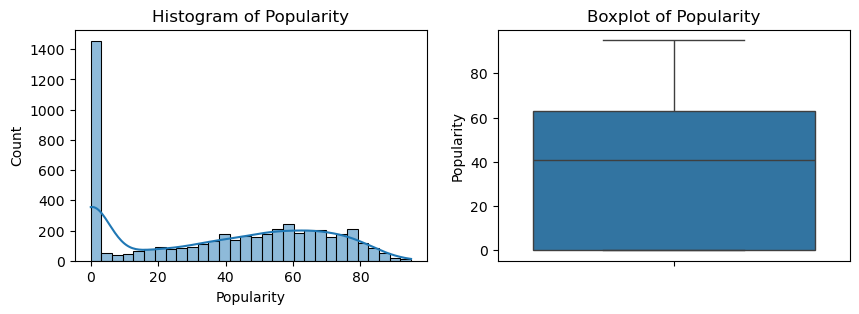

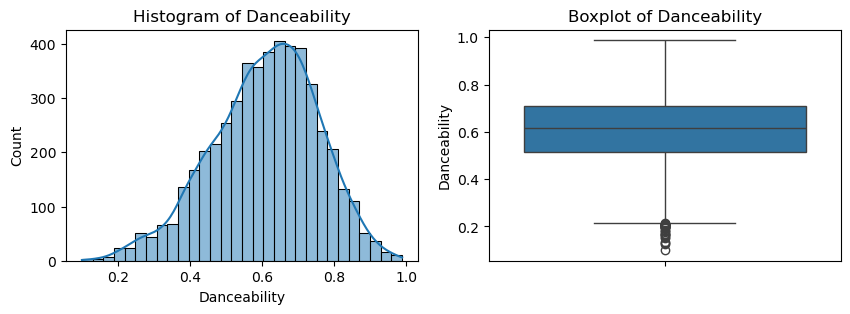

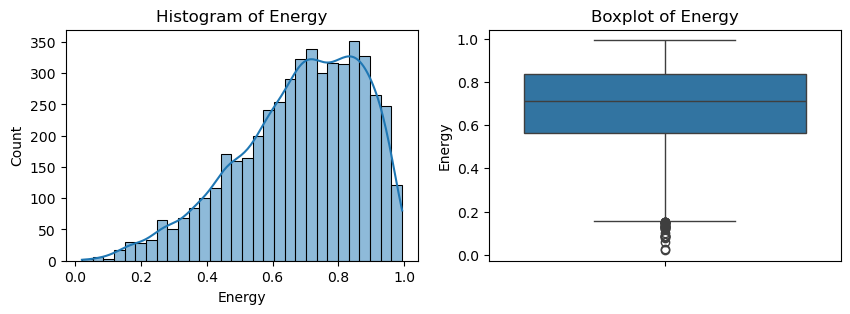

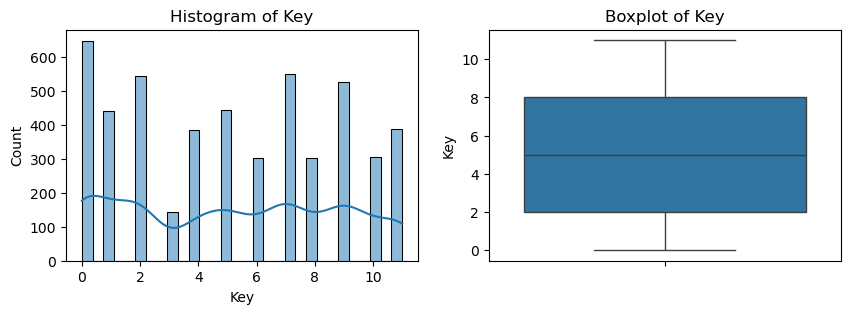

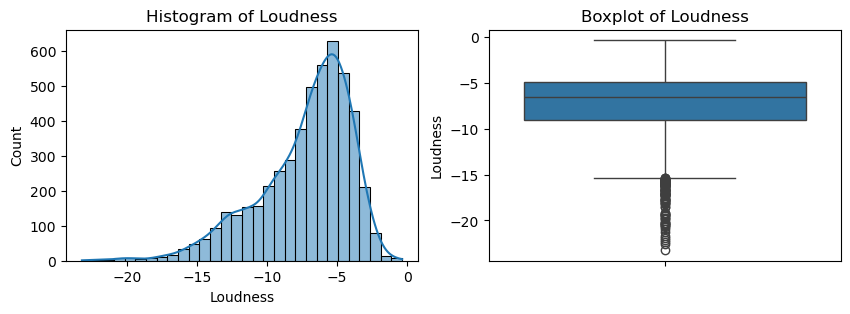

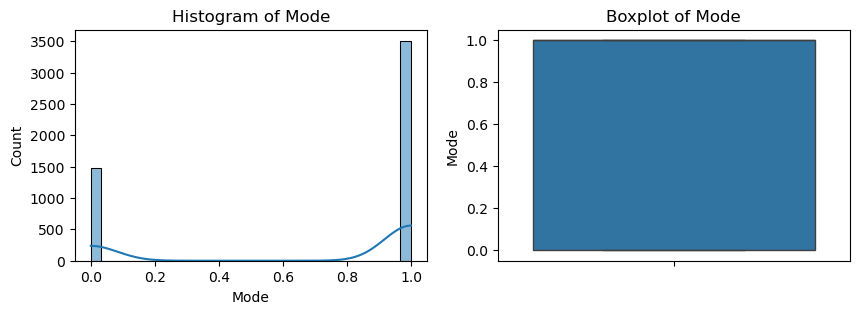

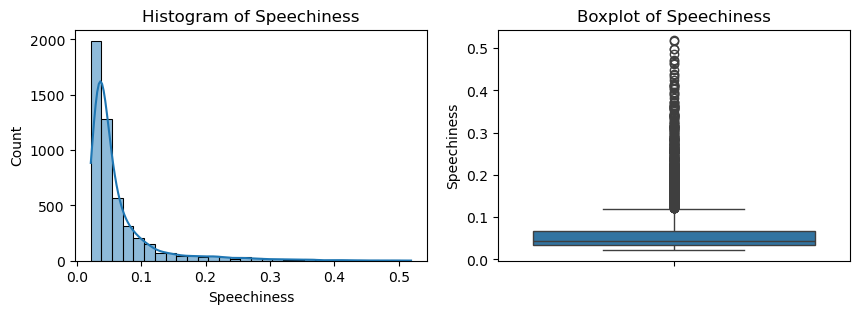

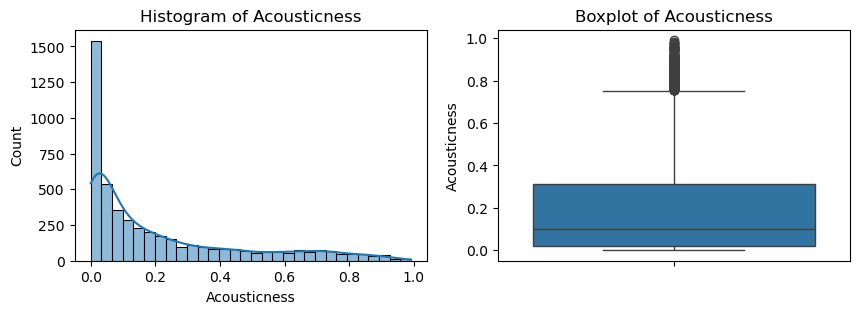

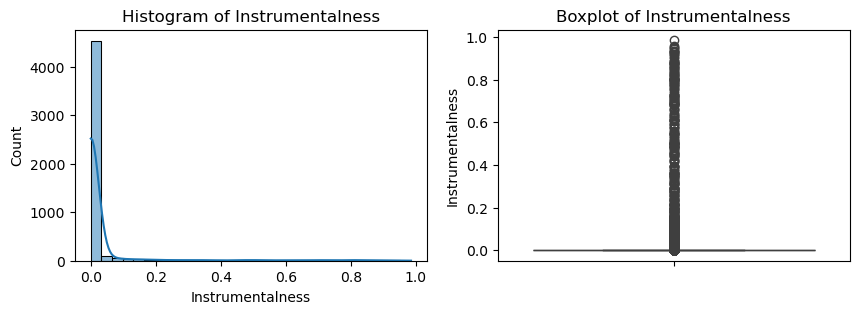

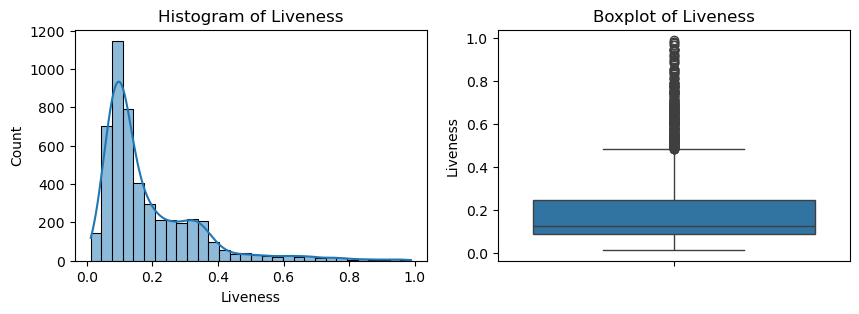

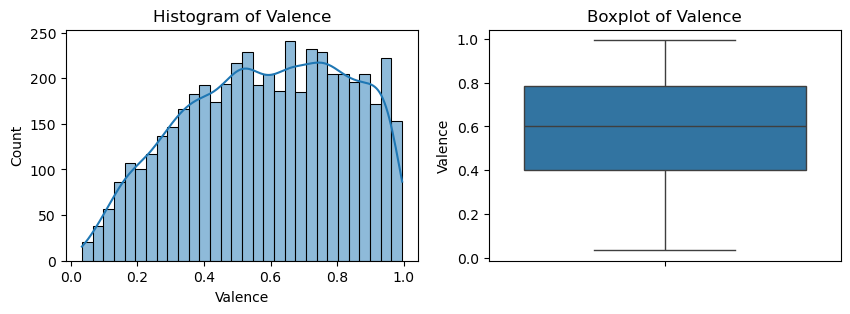

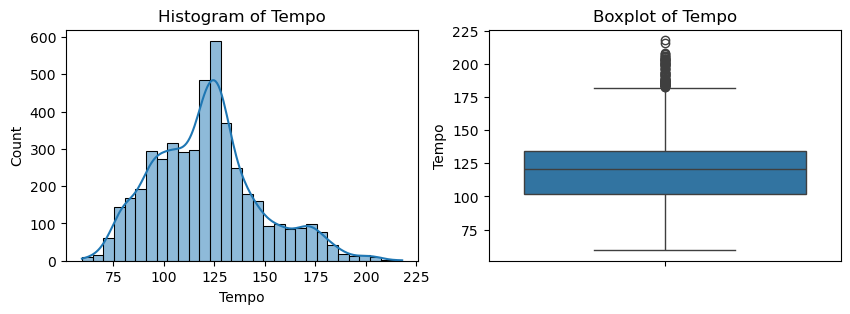

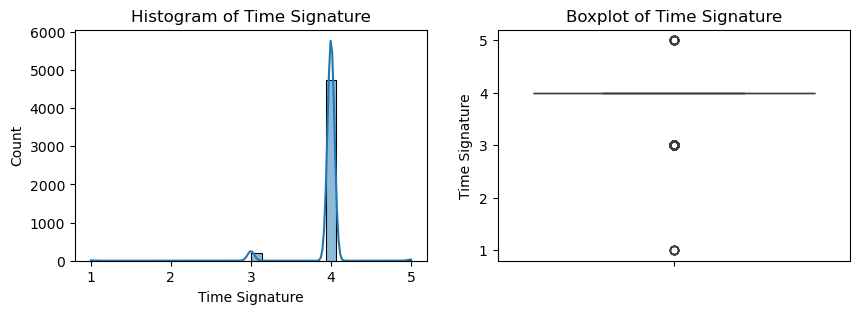

In [11]:
num_col = [c for c in df1.columns if df1[c].dtype != 'object']
def check_distribution_outliers(df, columns):
    for col in columns:
        plt.figure(figsize=(10, 3))

        # Histogram
        plt.subplot(1, 2, 1)
        sns.histplot(df[col], bins=30, kde=True)
        plt.title(f'Histogram of {col}')

        # Boxplot
        plt.subplot(1, 2, 2)
        sns.boxplot(y=df[col])
        plt.title(f'Boxplot of {col}')

        plt.show()

check_distribution_outliers(df1[num_col], num_col)

Terlihat bahwa numeric variable pada dataset ini memiliki distribusi yang skewed dan terdapat banyak outlier. Namun, nilai outlier masih masuk akal sehingga tidak perlu ditangani

## Missing Values

In [12]:
df1.isnull().sum()

Track Name              1
Artist Name(s)          1
Album Name              1
Album Release Date      0
Popularity              0
Artist Genres         295
Danceability            0
Energy                  0
Key                     0
Loudness                1
Mode                    0
Speechiness             0
Acousticness          150
Instrumentalness        0
Liveness                0
Valence                 0
Tempo                 250
Time Signature          0
dtype: int64

Terlihat bahwa ada missing value di Track Name. Karena kita ingin merekomendasikan lagu, maka harus ada Track Name, tetapi karena di row tersebut missing, maka akan saya drop row tersebut.

In [13]:
df2 = df1.dropna(subset = ['Track Name'])
df2 = df2.reset_index(drop=True)

In [14]:
df2.isnull().sum()

Track Name              0
Artist Name(s)          0
Album Name              0
Album Release Date      0
Popularity              0
Artist Genres         294
Danceability            0
Energy                  0
Key                     0
Loudness                1
Mode                    0
Speechiness             0
Acousticness          150
Instrumentalness        0
Liveness                0
Valence                 0
Tempo                 250
Time Signature          0
dtype: int64

Untuk missing di Artist Genres, saya akan menggunakan modus berdasarkan Artist Name(s), karena genre merupakan karakteristik artis dan relatif konsisten antar lagunya.

Untuk artist yang lagunya hanya satu di dataset ini, akan diimpute "Unknown". Tidak dilakukan impute dengan modus karena dapat menimbulkan bias. Selain itu, tidak dilakukan drop row karena dari 294 rows itu bisa saja masih mengandung fitur yang penting untuk membangun content-based recommendation system

In [15]:
df2["Artist Genres"] = (
    df2.groupby("Artist Name(s)")["Artist Genres"]
      .transform(lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else x)
)

df2["Artist Genres"] = df2["Artist Genres"].fillna("unknown")


Untuk Accousticness, Tempo, dan Loudness diimpute menggunakan median karena distribusinya skewed

In [16]:
df2['Tempo'] = df2['Tempo'].fillna(df2['Tempo'].median())
df2['Acousticness'] = df2['Acousticness'].fillna(df2['Acousticness'].median())
df2['Loudness'] = df2['Loudness'].fillna(df2['Loudness'].median())

In [17]:
df2.isnull().sum()

Track Name            0
Artist Name(s)        0
Album Name            0
Album Release Date    0
Popularity            0
Artist Genres         0
Danceability          0
Energy                0
Key                   0
Loudness              0
Mode                  0
Speechiness           0
Acousticness          0
Instrumentalness      0
Liveness              0
Valence               0
Tempo                 0
Time Signature        0
dtype: int64

## Visualisasi + Insight

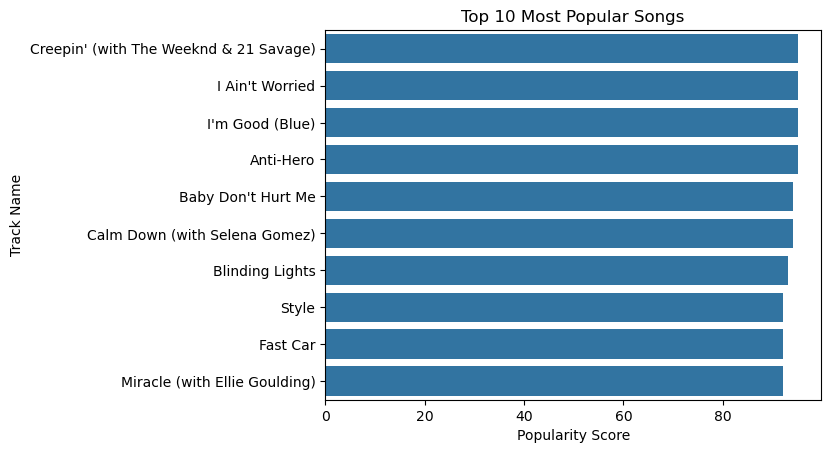

In [18]:
top_popular = (
    df2[['Track Name','Popularity']]
    .sort_values(by='Popularity', ascending=False)
    .head(10)
)

plt.figure()
sns.barplot(
    data=top_popular,
    x='Popularity',
    y='Track Name',
    order=top_popular['Track Name']  # JAGA URUTAN
)

plt.title('Top 10 Most Popular Songs')
plt.xlabel('Popularity Score')
plt.ylabel('Track Name')
plt.show()


Dari horizontal bar plot di atas didapat 10 track atau lagu paling populer berdasarkan popularity score. Didapat bahwa lagu paling populer adalah Creepin' (with The Weeknd & 21 Savage) diikuti  I'm Good (Blue) dan Anti-Hero pada posisi kedua dan ketiga. Tampaknya popularity score dari top 3 berbeda sangat tipis.

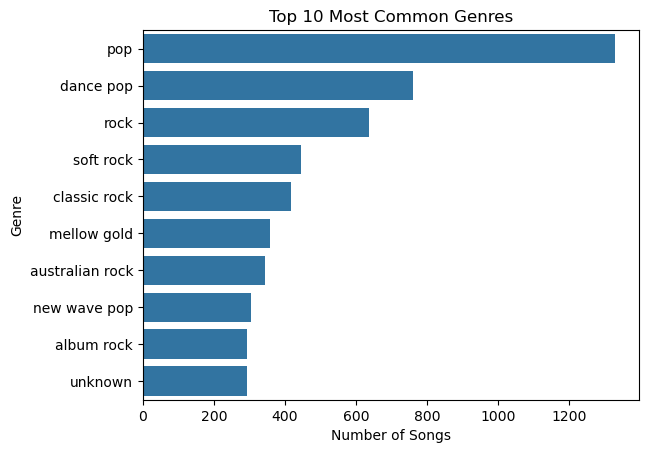

In [19]:
genre_count = (
    df2['Artist Genres']
    .str.split(',')
    .explode()
    .value_counts()
    .head(10)
)

genre_df = genre_count.reset_index()
genre_df.columns = ['Genre', 'Count']

plt.figure()
sns.barplot(
    data=genre_df,
    x='Count',
    y='Genre',
    order=genre_df.sort_values('Count', ascending=False)['Genre']
)

plt.title('Top 10 Most Common Genres')
plt.xlabel('Number of Songs')
plt.ylabel('Genre')
plt.show()


Di dataset ini didominasi oleh lagu dengan genre pop sekitar 1400 lagu. Genre ini cukup mendominasi di dataset ini yang hanya sebanyak 5000 lagu. Genre dance pop dan rock juga cukup mendominasi sebanyak lebih dari 600 lagu. Dari top 10 most common genre ini juga terlihat genre yang didominasi oleh pop dan rock

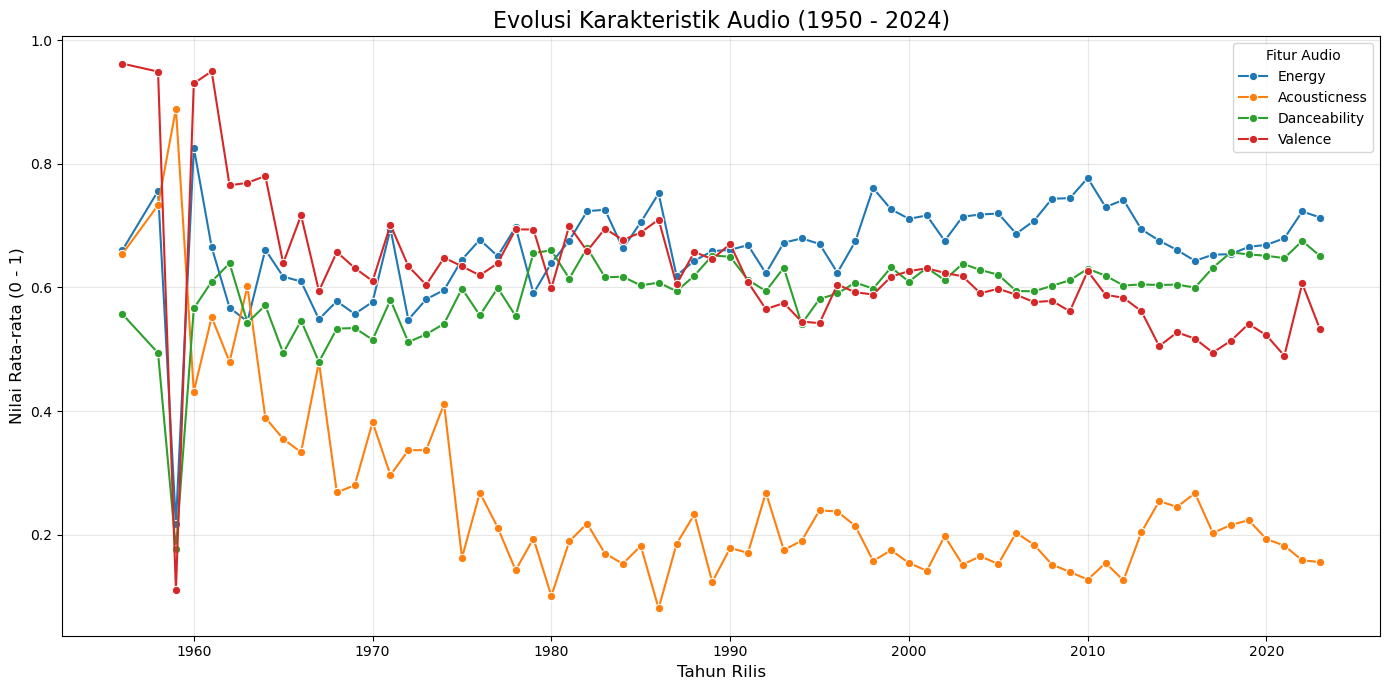

In [20]:
df3 = df2.copy()

df3['Release Year'] = pd.to_datetime(df3['Album Release Date'], errors='coerce').dt.year

df3_clean = df3.dropna(subset=['Release Year']).copy()

features_to_track = ['Energy', 'Acousticness', 'Danceability', 'Valence']

for feat in features_to_track:
    df3_clean[feat] = df3_clean[feat].fillna(df3_clean[feat].median())

yearly_avg = df3_clean.groupby('Release Year')[features_to_track].mean()

plt.figure(figsize=(14, 7))
for feat in features_to_track:
    sns.lineplot(data=yearly_avg, x=yearly_avg.index, y=feat, label=feat, marker='o')

plt.title('Evolusi Karakteristik Audio (1950 - 2024)', fontsize=16)
plt.xlabel('Tahun Rilis', fontsize=12)
plt.ylabel('Nilai Rata-rata (0 - 1)', fontsize=12)
plt.legend(title='Fitur Audio')
plt.grid(True, alpha=0.3)
plt.tight_layout()

Berdasarkan grafik “Evolusi Karakteristik Audio (1950–2024)”, terlihat bahwa selera dan cara produksi musik berubah cukup besar selama puluhan tahun. Perubahan yang paling jelas adalah pada Acousticness. Nilainya turun tajam sejak akhir 1950-an dan tetap rendah sampai sekarang. Ini menunjukkan bahwa musik modern semakin jarang menggunakan alat musik akustik, dan lebih banyak memakai instrumen elektrik serta teknologi digital. Sebaliknya, Energy terus meningkat dari waktu ke waktu. Artinya, musik sekarang cenderung terdengar lebih keras, lebih cepat, dan lebih intens dibandingkan musik di masa lalu.

Untuk suasana lagu, variabel Valence (tingkat keceriaan) menunjukkan tren menurun. Pada era 1950-an musik cenderung lebih ceria, tetapi sejak tahun 2000-an banyak lagu populer memiliki nuansa yang lebih sedih, serius, atau gelap. Sementara itu, Danceability relatif stabil dan bahkan sedikit meningkat sejak 1980-an. Ini berarti ritme yang enak untuk berdansa tetap penting dan menjadi salah satu daya tarik utama musik hingga sekarang.

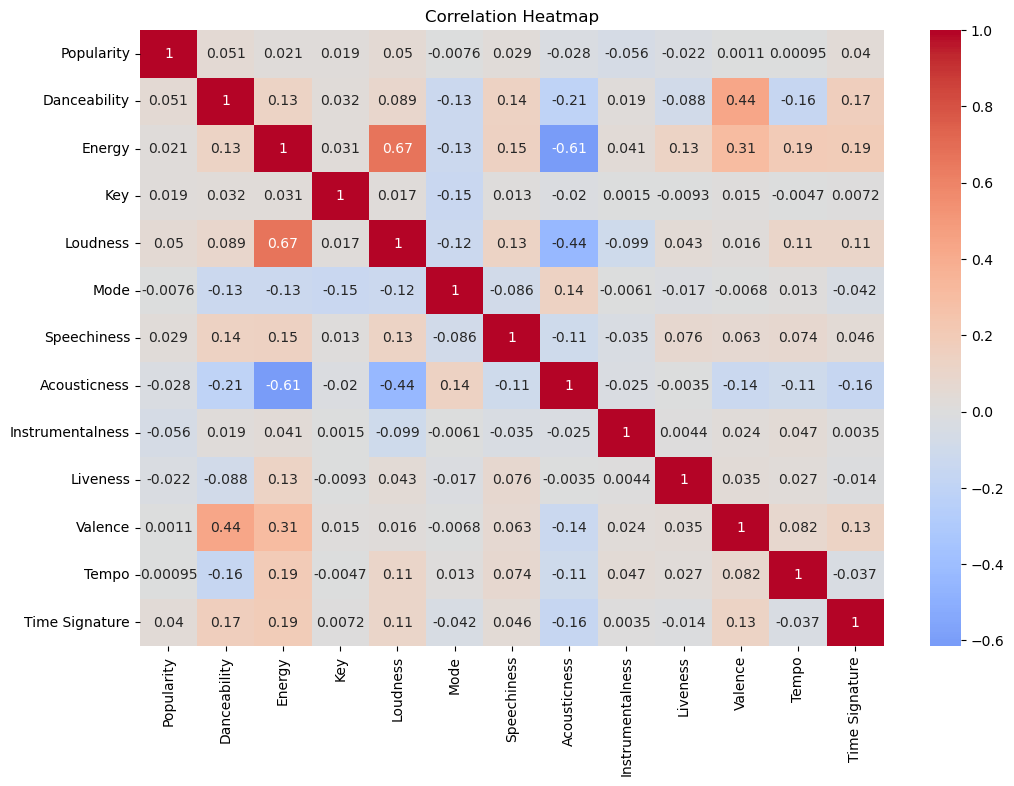

In [21]:
plt.figure(figsize=(12,8))
sns.heatmap(df2[num_col].corr(), cmap="coolwarm", center=0, annot = True)
plt.title("Correlation Heatmap")
plt.show()

Terlihat bahwa Loudness memiliki korelasi dengan Energy uang cukup kuat, yaitu sekitar 0.67. Hal ini menunjukkan bahwa lagu yang terdengar lebih keras umumnya juga memiliki tingkat energi yang lebih tinggi, sehingga keduanya mencerminkan intensitas sonik yang saling berkaitan erat.

Sementara itu, Acousticness dan Energy menunjukkan korelasi negatif yang cukup kuat dimana semakin tinggi penggunaan instrumen akustik, semakin rendah tingkat energi lagu tersebut. Ini mengindikasikan bahwa lagu akustik cenderung memiliki karakter yang lebih lembut dan tidak terlalu intens dibandingkan lagu dengan dominasi instrumen elektrik atau digital.

Selain itu, Valence dan Danceability memiliki korelasi moderat (0.44). Artinya, lagu yang lebih ceria cenderung sedikit lebih mudah untuk berdansa, meskipun hubungan ini tidak terlalu kuat.

# B) Making Recommendation System

Untuk membuat song recommendation system ini, digunakan audio features yang merepresentasikan karakteristik perseptual lagu dan cocok untuk perhitungan cosine similarity. Popularity juga tidak disertakan karena mencerminkan preferensi pengguna secara global, bukan karakteristik konten lagu.

In [22]:
audio_features = [
    "Danceability", "Energy", "Loudness", "Speechiness",
    "Acousticness", "Instrumentalness", "Liveness",
    "Valence", "Tempo", "Key", 'Mode', 'Time Signature'
]

scaler = RobustScaler()
audio_scaled = scaler.fit_transform(df2[audio_features])


In [23]:
cos_sim = cosine_similarity(audio_scaled, audio_scaled)
def recommend_songs(track_name, n=5):

    # Cek apakah lagu ada di dataset
    if track_name not in df2['Track Name'].values:
        return "Lagu tidak ditemukan dalam dataset"

    # Ambil index lagu
    idx = df2[df2['Track Name'] == track_name].index[0]

    # Ambil similarity score
    sim_scores = list(enumerate(cos_sim[idx]))

    # Urutkan dari paling mirip
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Ambil n lagu teratas (kecuali dirinya sendiri)
    sim_scores = sim_scores[1:n+1]

    # Ambil informasi lagu
    recommended_idx = [i[0] for i in sim_scores]

    return df2.iloc[recommended_idx][
        ['Track Name', 'Artist Name(s)', 'Artist Genres', 'Popularity']
    ]


In [24]:
recommend_songs("Style")

,Track Name,Artist Name(s),Artist Genres,Popularity
2100,Kosciusko - Remastered Version,Midnight Oil,australian rock,25
4978,Princess of China - Radio Edit,"Coldplay, Rihanna","permanent wave,pop,barbadian pop,pop,urban con...",54
2442,MMMBop,Hanson,boy band,73
3031,All The Things She Said,t.A.T.u.,"dance pop,europop,girl group",0
2234,You Know I'm No Good,Amy Winehouse,"british soul,neo soul",0


# C) Examine Output

In [25]:
def prove_similarity(input_song_name, recommended_songs_list):
    input_data = df2[df2['Track Name'].str.lower() == input_song_name.lower()].head(1)

    rec_data = df2[df2['Track Name'].isin(recommended_songs_list)]

    comparison = pd.concat([input_data, rec_data])

    plt.figure(figsize=(12, 6))
    for i, row in comparison.iterrows():
        is_input = row['Track Name'].lower() == input_song_name.lower()
        plt.plot(audio_features, row[audio_features],
                 marker='o' if is_input else 'x',
                 linewidth=4 if is_input else 1,
                 label=f"{'[INPUT] ' if is_input else ''}{row['Track Name']}")

    plt.title(f"Bukti Kemiripan Audio: {input_song_name}")
    plt.ylabel("Nilai Normalisasi (0-1)")
    plt.xticks(rotation=45)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.show()

    input_vals = input_data[audio_features].values
    rec_vals = rec_data[audio_features].mean().values
    diff = abs(input_vals - rec_vals)

    print("\n--- Rata-rata Selisih Fitur (Semakin kecil semakin mirip) ---")
    for feat, d in zip(audio_features, diff[0]):
        print(f"{feat}: {d:.4f}")

In [26]:
# Lagu 1
recommend_songs("Style")

,Track Name,Artist Name(s),Artist Genres,Popularity
2100,Kosciusko - Remastered Version,Midnight Oil,australian rock,25
4978,Princess of China - Radio Edit,"Coldplay, Rihanna","permanent wave,pop,barbadian pop,pop,urban con...",54
2442,MMMBop,Hanson,boy band,73
3031,All The Things She Said,t.A.T.u.,"dance pop,europop,girl group",0
2234,You Know I'm No Good,Amy Winehouse,"british soul,neo soul",0


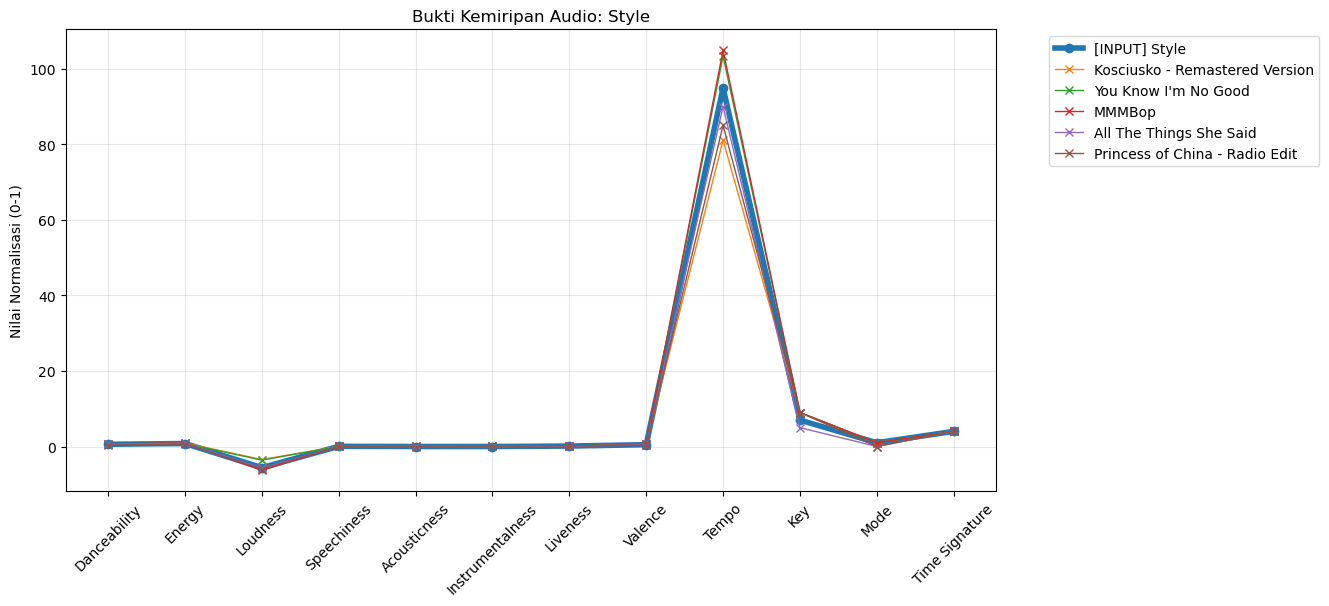


--- Rata-rata Selisih Fitur (Semakin kecil semakin mirip) ---
Danceability: 0.0054
Energy: 0.0484
Loudness: 0.5904
Speechiness: 0.0022
Acousticness: 0.0116
Instrumentalness: 0.0031
Liveness: 0.0058
Valence: 0.0430
Tempo: 2.0568
Key: 1.2000
Mode: 0.4000
Time Signature: 0.0000


In [27]:
recs1 = ["Kosciusko - Remastered Version", "Princess of China - Radio Edit", "MMMBop", "All The Things She Said", "You Know I'm No Good"]
prove_similarity("Style", recs1)

In [28]:
recommend_songs("Kung Fu Fighting")

,Track Name,Artist Name(s),Artist Genres,Popularity
3645,Djapana - Radio Mix,Yothu Yindi,"australian indigenous,didgeridoo",0
4430,I Wish,Stevie Wonder,"motown,soul",0
1225,The Rhythm of the Jungle,The Quick,unknown,19
3984,Edge of the Night,Sheppard,"australian indie,folk-pop",20
2025,New Rules,Dua Lipa,"dance pop,pop,uk pop",84


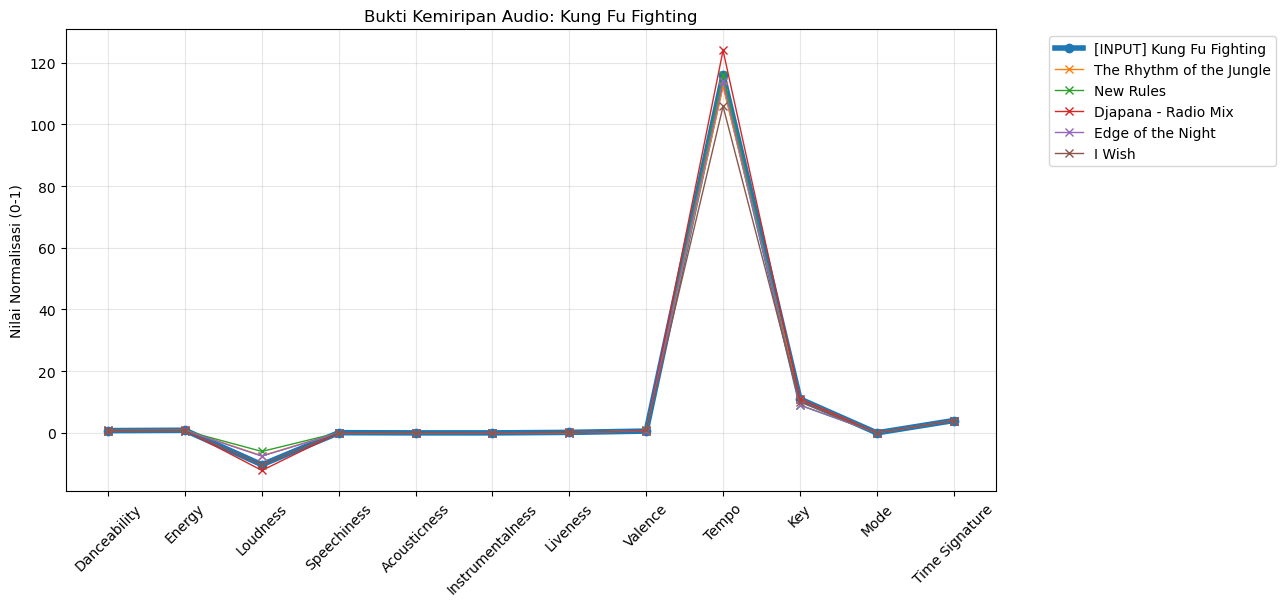


--- Rata-rata Selisih Fitur (Semakin kecil semakin mirip) ---
Danceability: 0.0238
Energy: 0.0740
Loudness: 1.6088
Speechiness: 0.0096
Acousticness: 0.0544
Instrumentalness: 0.0000
Liveness: 0.0577
Valence: 0.1352
Tempo: 1.5734
Key: 1.0000
Mode: 0.0000
Time Signature: 0.0000


In [29]:
recs2 = ['Djapana - Radio Mix', 'I Wish', 'The Rhythm of the Jungle', 'Edge of the Night', 'New Rules']
prove_similarity("Kung Fu Fighting", recs2)

In [30]:
#Lagu 3
recommend_songs("Truly")

,Track Name,Artist Name(s),Artist Genres,Popularity
417,How Can You Mend A Broken Heart,Bee Gees,"disco,mellow gold,soft rock",65
2630,I Will Always Love You,Whitney Houston,dance pop,81
1298,Everything I Own,Bread,"folk rock,mellow gold,singer-songwriter,soft rock",74
1329,You're The Reason I'm Living,Bobby Darin,"adult standards,easy listening,lounge,rock-and...",1
1269,Ben - Single Version,Michael Jackson,"r&b,soul",63


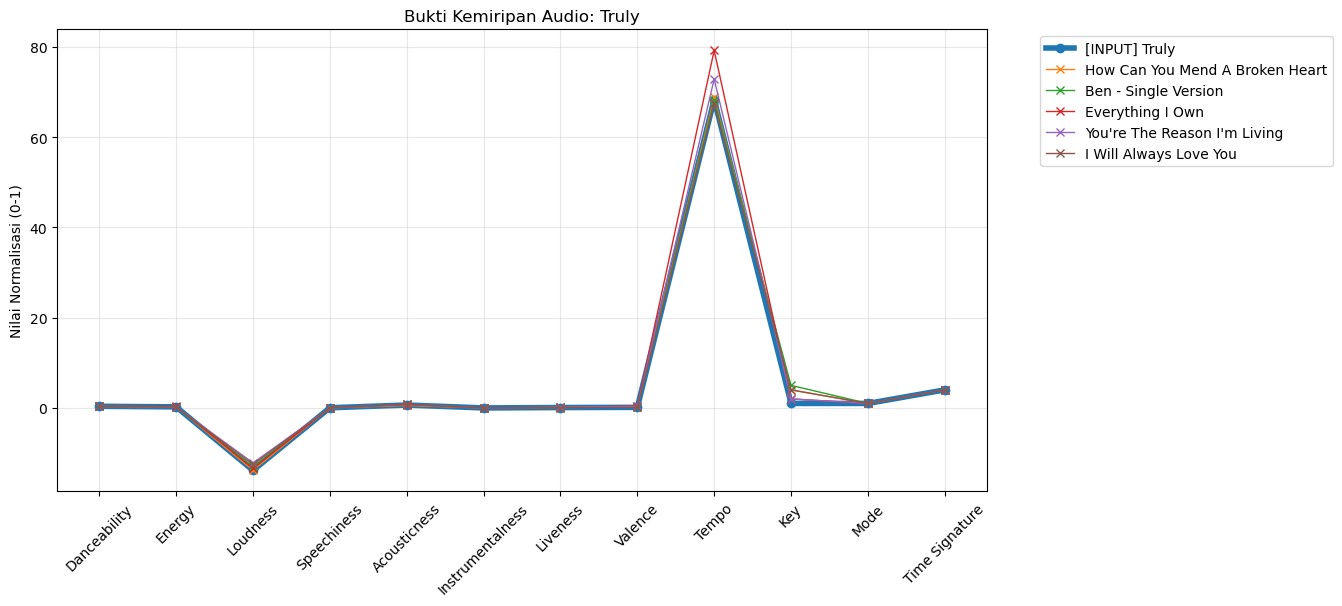


--- Rata-rata Selisih Fitur (Semakin kecil semakin mirip) ---
Danceability: 0.0038
Energy: 0.0040
Loudness: 0.8796
Speechiness: 0.0058
Acousticness: 0.1042
Instrumentalness: 0.0000
Liveness: 0.0233
Valence: 0.1510
Tempo: 2.9670
Key: 2.4000
Mode: 0.0000
Time Signature: 0.0000


In [31]:
recs3 = ['How Can You Mend A Broken Heart', 'I Will Always Love You', 'Everything I Own', "You're The Reason I'm Living", 'Ben - Single Version']
prove_similarity("Truly", recs3)